# Лабораторная работа 2. Спектральная теория случайных матриц

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import scipy

rng = np.random.default_rng(seed=69)

## Задание 1. Шумовой балк Марченко–Пастура

**Что делаем.** Пишем функции:
- `spectrum(p, n)` генерирует белый шум $X \in \mathbb{R}^{p\times n}$, $X_{ij} \sim \mathcal{N}(0, \sigma^2)$, считает выборочную ковариацию $\hat\Sigma = \frac{1}{n}XX^T$ и возвращает её собственные числа (`eigvalsh` нужна для симметричных матриц и отдаёт числа по возрастанию);
- `mp_bounds` возвращает границы балка $\lambda_\pm = \sigma^2(1 \pm \sqrt{\gamma})^2$, где $\gamma = p/n$;
- `mp_density` считает теоретическую плотность $\rho_{MP}(\lambda) = \frac{\sqrt{(\lambda_+ - \lambda)(\lambda - \lambda_-)}}{2\pi\sigma^2\gamma\lambda}$ на отрезке $[\lambda_-, \lambda_+]$;
- `drop_zeros` выкидывает машинные нули.

**Зачем.** Собственное число ковариации — это дисперсия данных вдоль одного из главных направлений (именно их показывает PCA). У белого шума с $\sigma^2 = 1$ истинная дисперсия в любом направлении равна 1, поэтому наивно ждёшь, что все собственные числа будут около 1. Закон Марченко–Пастура говорит, что при $p$ и $n$ одного порядка они размазываются по всему отрезку $[\lambda_-, \lambda_+]$. Это и проверяем.

**Как рассказать.** «Порог для нулей — машинная точность float64 ($\approx 2\cdot10^{-16}$), умноженная на наибольшее собственное число и размер матрицы. Ошибки округления меньше этой величины, а настоящие собственные числа намного больше. По тому же правилу ранг считает `np.linalg.matrix_rank`.»

In [2]:
def spectrum(p, n, sigma2=1.0):
    X = rng.normal(0, np.sqrt(sigma2), (p, n))
    return np.linalg.eigvalsh(X @ X.T / n)

def mp_bounds(gamma, sigma2=1.0):
    return sigma2 * (1 - np.sqrt(gamma))**2, sigma2 * (1 + np.sqrt(gamma))**2

def mp_density(gamma, sigma2=1.0):
    lam_minus, lam_plus = mp_bounds(gamma, sigma2)
    x = np.linspace(lam_minus, lam_plus, 500)
    return x, np.sqrt((lam_plus - x) * (x - lam_minus)) / (2 * np.pi * sigma2 * gamma * x)

def drop_zeros(lam):
    return lam[lam > lam.max() * len(lam) * np.finfo(float).eps]

**Что делаем.** При $n = 1000$ берём два режима: A — $p = 500$ ($\gamma = 0.5$, полный ранг), B — $p = 2000$ ($\gamma = 2$, дефект ранга). Для каждого строим гистограмму собственных чисел, поверх неё кривую $\rho_{MP}$, пунктиром границы $\lambda_\pm$, а теорию и эксперимент сводим в таблицу.

**Ловушка 1: нули.** При $p > n$ ранг $\hat\Sigma$ не больше $n$, поэтому ровно $p - n = 1000$ собственных чисел равны нулю. Численно они выходят порядка $\pm10^{-15}$, и фильтр `eigs > 0` оставит примерно половину из них (видно в выводе ниже). Порог `drop_zeros` около $10^{-12}$, а самое маленькое настоящее число около $\lambda_- \approx 0.17$, так что запас в обе стороны огромный.

**Ловушка 2: масштаб.** Полная мера МП — это $(1 - 1/\gamma)\,\delta_0 + \rho_{MP}$. Пик в нуле забирает массу $1 - 1/\gamma = 0.5$, поэтому $\int\rho_{MP}\,d\lambda = 1/\gamma = 0.5$. Гистограмма с `density=True` построена только по ненулевым числам и нормирована на 1, то есть это условная плотность:
$$\rho(\lambda \mid \lambda > 0) = \frac{\rho_{MP}(\lambda)}{P(\lambda > 0)} = \frac{\rho_{MP}(\lambda)}{1/\gamma} = \gamma\,\rho_{MP}(\lambda).$$
Поэтому при $\gamma > 1$ кривую умножаем на $\gamma$. При $\gamma \le 1$ нулей нет и множитель равен 1, отсюда `max(gamma, 1)`.

**Как рассказать.** «Слева гистограмма ложится на кривую без всяких поправок. Справа признаков больше, чем наблюдений, и половина собственных чисел нулевые. Их я отрезал порогом по машинной точности, а кривую умножил на $\gamma = 2$: теоретическая плотность ненулевой части интегрируется в $1/\gamma$, а гистограмма — в 1.»

γ = 0.5: всего 500, eigs > 0: 500, после drop_zeros: 500


γ = 2.0: всего 2000, eigs > 0: 1496, после drop_zeros: 1000


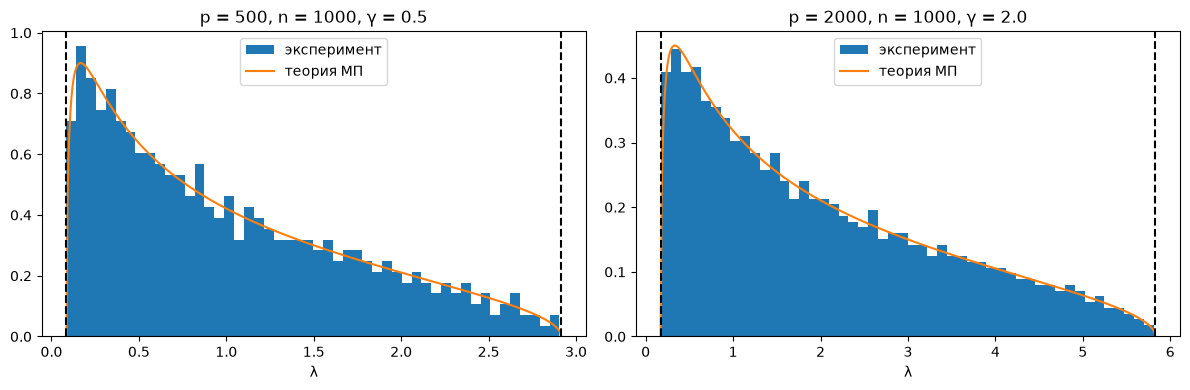

,λ− теория,λmin эксперимент,λ+ теория,λmax эксперимент
γ,,,,
0.5,0.0858,0.0859,2.9142,2.9048
2.0,0.1716,0.1806,5.8284,5.8093


In [3]:
n = 1000
rows = []
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, p in zip(axes, [500, 2000]):
    gamma = p / n
    lam_minus, lam_plus = mp_bounds(gamma)
    lam = spectrum(p, n)
    print(f'γ = {gamma}: всего {p}, eigs > 0: {(lam > 0).sum()}, после drop_zeros: {len(drop_zeros(lam))}')
    lam = drop_zeros(lam)

    x, rho = mp_density(gamma)
    ax.hist(lam, bins=50, density=True, label='эксперимент')
    ax.plot(x, rho * max(gamma, 1), label='теория МП')
    ax.axvline(lam_minus, ls='--', c='k')
    ax.axvline(lam_plus, ls='--', c='k')
    ax.set_title(f'p = {p}, n = {n}, γ = {gamma}')
    ax.set_xlabel('λ')
    ax.legend()

    rows.append({
        'γ': gamma,
        'λ− теория': lam_minus,
        'λmin эксперимент': lam.min(),
        'λ+ теория': lam_plus,
        'λmax эксперимент': lam.max(),
    })

fig.tight_layout()
plt.show()
pd.DataFrame(rows).set_index('γ').round(4)

**Что делаем.** Повторяем режим A 200 раз и смотрим, где оказывается $\hat\lambda_{max}$ относительно $\lambda_+$. Отклонение делим на масштаб флуктуаций края из конспекта: $s = (1+\sqrt{\gamma})^{4/3}\gamma^{-1/6}n^{-2/3} \approx 0.023$. Последней строкой считаем $\hat\lambda_{max}$ для $p = n = 1000$.

**Зачем.** Это ответы на вопросы задания: совпадает ли $\hat\lambda_{max}$ с $\lambda_+$, каким распределением описываются флуктуации и почему при $\gamma = 1$ максимум стремится к 4.

**Как рассказать.** «$\lambda_+$ — это предел при $n \to \infty$. При конечном $n$ максимум случаен и гуляет вокруг $\lambda_+$ на величину порядка $n^{-2/3}$. Нормированное отклонение подчиняется распределению Трейси–Видома $TW_1$: среднее $\approx -1.21$, стандартное отклонение $\approx 1.27$, правый хвост длиннее левого. Поэтому максимум бывает и левее, и правее границы, и превышение $\lambda_+$ на пару сотых ещё не говорит о сигнале.»

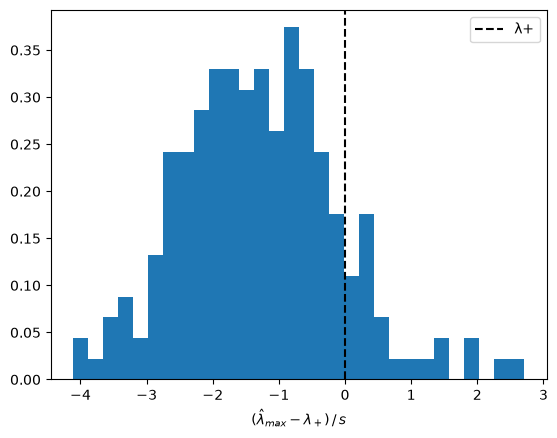

масштаб s = 0.0229
среднее = -1.29, ст. откл. = 1.18, правее λ+ в 12% случаев
p = n = 1000: λmax = 4.020


In [4]:
p, n = 500, 1000
gamma = p / n
lam_plus = mp_bounds(gamma)[1]
s = (1 + np.sqrt(gamma))**(4 / 3) * gamma**(-1 / 6) * n**(-2 / 3)
tw = np.array([(spectrum(p, n).max() - lam_plus) / s for _ in range(200)])

fig, ax = plt.subplots()
ax.hist(tw, bins=30, density=True)
ax.axvline(0, ls='--', c='k', label='λ+')
ax.set_xlabel(r'$(\hat\lambda_{max} - \lambda_+)\,/\,s$')
ax.legend()
plt.show()

print(f'масштаб s = {s:.4f}')
print(f'среднее = {tw.mean():.2f}, ст. откл. = {tw.std():.2f}, правее λ+ в {(tw > 0).mean():.0%} случаев')
print(f'p = n = 1000: λmax = {spectrum(1000, 1000).max():.3f}')

## Задание 2. Фазовый переход BBP

**Что делаем.** Прячем в шум один сигнал силы $\theta$ вдоль направления $v_1 = e_1 = [1, 0, \dots, 0]^T$: $Y = (I_p + \theta v_1v_1^T)^{1/2}X$. Так как $v_1$ — первый базисный вектор, это просто умножение первой строки $X$ на $\sqrt{1+\theta}$: дисперсия первого признака становится $1 + \theta$, у остальных остаётся 1. Для каждого $\theta$ от 0.1 до 2.5 с шагом 0.1 делаем $M = 5$ генераций и считаем старшее собственное число $\hat\lambda_1$ матрицы $\frac{1}{n}YY^T$ и перекрытие $|\langle\hat v_1, v_1\rangle|^2$. Так как $v_1 = e_1$, перекрытие — это просто квадрат первой координаты $\hat v_1$. Результаты усредняем.

**Зачем.** Хотим увидеть, начиная с какой силы сигнала PCA вообще способен его заметить.

**Как считаем быстро.** Если $Y = USV^T$ (SVD), то $\frac{1}{n}YY^T = U\frac{S^2}{n}U^T$. Значит, собственные числа ковариации равны $s_i^2/n$, а собственные векторы — это левые сингулярные векторы $Y$. Нужна только старшая компонента, поэтому вызываем `scipy.sparse.linalg.svds(Y, k=1)`: она находит одну наибольшую тройку итерациями из умножений матрицы на вектор и не строит матрицу $1500\times1500$ целиком.

**Ловушка.** `np.linalg.eigh` возвращает собственные числа по возрастанию, поэтому главная компонента там последняя: `w[-1]` и столбец `V[:, -1]`. Индекс `[0]` дал бы наименьшее число, которое прижато к $\lambda_-$, и вектор, ортогональный сигналу. `svds(k=1)` сразу возвращает наибольшую тройку.

**Как рассказать.** «Сигнал — это повышенная дисперсия вдоль одного направления. Генерирую шум, усиливаю первую строку и через частичное SVD беру старшую компоненту. Дальше смотрю на два числа: насколько велико $\hat\lambda_1$ и насколько найденное направление совпадает с истинным.»

In [5]:
p, n = 1500, 3000
gamma = p / n
theta_c = np.sqrt(gamma)
lam_plus = mp_bounds(gamma)[1]

def top_component(theta):
    X = rng.standard_normal((p, n))
    X[0] *= np.sqrt(1 + theta)
    u, s, _ = scipy.sparse.linalg.svds(X, k=1)
    return s[0]**2 / n, u[0, 0]**2

thetas = np.linspace(0.1, 2.5, 25)
M = 5
res = np.array([[top_component(t) for _ in range(M)] for t in thetas]).mean(axis=1)
lam1, overlap = res[:, 0], res[:, 1]

**Что делаем.** Накладываем на эксперимент теорию BBP: $\hat\lambda_1 \to \lambda_+$ при $\theta \le \theta_c = \sqrt{\gamma} \approx 0.707$ и $\hat\lambda_1 \to (1+\theta)(1+\gamma/\theta)$ при $\theta > \theta_c$. Для перекрытия предел Пола — Бенайча-Жорже: 0 ниже порога и $\frac{1-\gamma/\theta^2}{1+\gamma/\theta}$ выше. Пунктиром отмечаем $\theta_c$.

**Ловушка.** Формула $(1+\theta)(1+\gamma/\theta)$ при малых $\theta$ уходит в бесконечность из-за слагаемого $\gamma/\theta$. Она верна только выше порога, а ниже порога теория — константа $\lambda_+$. Поэтому теория задаётся кусочно через `np.where`.

**Как рассказать.** «Ниже порога $\hat\lambda_1$ прилипает к краю шума $\lambda_+$, а перекрытие около нуля: PCA выдаёт случайное направление и сигнала не видит. Выше порога собственное число выскакивает из балка, а перекрытие растёт, но остаётся меньше единицы, то есть найденный вектор всё ещё скошен шумом. Около $\theta_c$ точки идут плавно, потому что при конечных $p$ и $n$ излом размывается.»

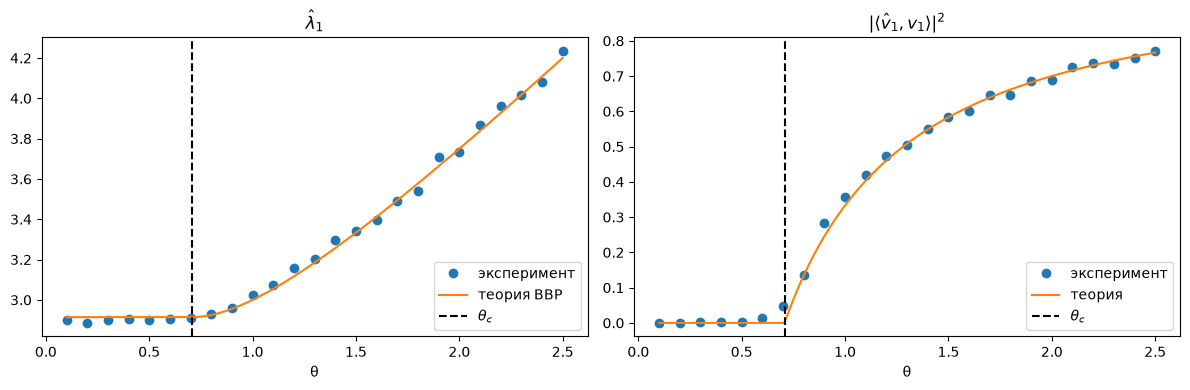

In [6]:
def bbp_lambda(theta):
    return np.where(theta > theta_c, (1 + theta) * (1 + gamma / theta), lam_plus)

def bbp_overlap(theta):
    return np.where(theta > theta_c, (1 - gamma / theta**2) / (1 + gamma / theta), 0)

t = np.linspace(0.1, 2.5, 500)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(thetas, lam1, 'o', label='эксперимент')
axes[0].plot(t, bbp_lambda(t), label='теория BBP')
axes[0].set_title(r'$\hat\lambda_1$')
axes[1].plot(thetas, overlap, 'o', label='эксперимент')
axes[1].plot(t, bbp_overlap(t), label='теория')
axes[1].set_title(r'$|\langle\hat v_1, v_1\rangle|^2$')
for ax in axes:
    ax.axvline(theta_c, ls='--', c='k', label=r'$\theta_c$')
    ax.set_xlabel('θ')
    ax.legend()
fig.tight_layout()
plt.show()

**Что делаем.** Выше порога $\hat\lambda_1 = (1+\theta)(1+\gamma/\theta) = 1 + \theta + \gamma + \gamma/\theta$, то есть наивная оценка $\hat\lambda_1 - 1$ завышает $\theta$ на $\gamma + \gamma/\theta$. Обращаем формулу: это квадратное уравнение относительно $1+\theta$, и его больший корень даёт
$$\hat\theta = \frac{\hat\lambda_1 + 1 - \gamma + \sqrt{(\hat\lambda_1 + 1 - \gamma)^2 - 4\hat\lambda_1}}{2} - 1.$$
`calibrate` — это guard clause: если $\hat\lambda_1 \le \lambda_+$, функция возвращает вердикт «сигнала нет», иначе $\hat\theta$.

**Зачем guard.** Подкоренное выражение неотрицательно только при $\hat\lambda_1 \ge \lambda_+$ (или $\le \lambda_-$). Внутри балка формула не определена, и смысла в ней нет: такое $\hat\lambda_1$ шум даёт и без всякого сигнала.

**Как рассказать.** «Наивно сила сигнала равна $\hat\lambda_1 - 1$, но шум выталкивает собственное число вверх. Обращаю формулу BBP и получаю несмещённую оценку. Если $\hat\lambda_1$ не вышло за $\lambda_+$, честный ответ — сигнал не обнаружен.»

θ = 0.1, λ1 = 2.902: Сигнал отсутствует или находится ниже предела детектирования
θ = 0.7, λ1 = 2.908: Сигнал отсутствует или находится ниже предела детектирования
θ = 1.3, λ1 = 3.202: 1.3244232724104266
θ = 1.9, λ1 = 3.710: 1.9545678003114322
θ = 2.5, λ1 = 4.235: 2.538241105491122


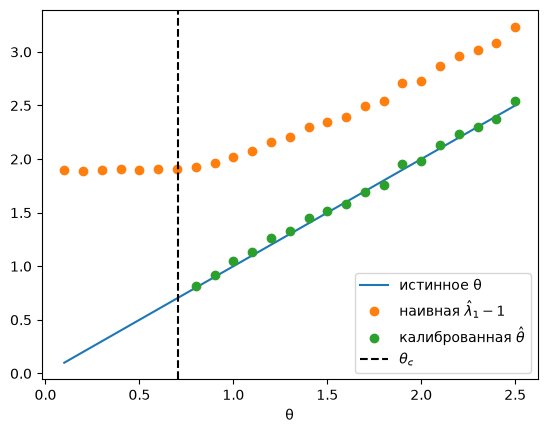

In [7]:
def calibrate(lam):
    if lam <= lam_plus:
        return 'Сигнал отсутствует или находится ниже предела детектирования'
    b = lam + 1 - gamma
    return (b + np.sqrt(b**2 - 4 * lam)) / 2 - 1

for t, lam in zip(thetas[::6], lam1[::6]):
    print(f'θ = {t:.1f}, λ1 = {lam:.3f}: {calibrate(lam)}')

theta_hat = [c if isinstance(c, float) else np.nan for c in map(calibrate, lam1)]

fig, ax = plt.subplots()
ax.plot(thetas, thetas, label='истинное θ')
ax.plot(thetas, lam1 - 1, 'o', label=r'наивная $\hat\lambda_1 - 1$')
ax.plot(thetas, theta_hat, 'o', label=r'калиброванная $\hat\theta$')
ax.axvline(theta_c, ls='--', c='k', label=r'$\theta_c$')
ax.set_xlabel('θ')
ax.legend()
plt.show()

## Задание 3. Спектральная диагностика ResNet-18

**Что делаем.** Загружаем предобученную ResNet-18 и пишем `esd(W)` — спектр корреляционной матрицы слоя $S = \frac{1}{N}WW^T$, где $N = \max(M, K)$. Свёрточный тензор формы $(C_{out}, C_{in}, K, K)$ разворачиваем в матрицу $C_{out}\times(C_{in}K^2)$, где каждая строка — один фильтр. Матрица `fc` уже двумерная, и `reshape` её не меняет.

**Как считаем быстро.** Собственные числа $\frac{1}{N}WW^T$ (и $\frac{1}{N}W^TW$) — это $s_i^2/N$, где $s_i$ — сингулярные числа $W$. Их ровно $\min(M, K)$, так что лишних нулей нет. У `layer4.1.conv2` выходит 512 чисел вместо матрицы $4608\times4608$, в которой 4096 собственных чисел были бы машинными нулями.

**Зачем.** По теории Мартина–Махони (HTSR) у необученного слоя спектр выглядит как балк Марченко–Пастура, а у обученного вырастает степенной хвост $\rho(\lambda) \propto \lambda^{-\alpha}$. По показателю $\alpha$ можно судить о слое без тестовых данных.

In [8]:
import torchvision.models as models

model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)

def get_weight(name):
    return model.get_submodule(name).weight.detach().numpy()

def esd(W):
    W = W.reshape(len(W), -1)
    s = np.linalg.svd(W, compute_uv=False)
    return s**2 / max(W.shape)

W = get_weight('layer4.1.conv2')
lam = esd(W)
print(f'{W.shape} -> {W.reshape(len(W), -1).shape}, собственных чисел: {len(lam)}')

(512, 512, 3, 3) -> (512, 4608), собственных чисел: 512


**Что делаем.** Наивная оценка $\alpha$: строим обычную гистограмму с линейными бинами, логарифмируем ($\ln\rho = -\alpha\ln\lambda + c$) и проводим прямую методом наименьших квадратов. Повторяем для разного числа бинов.

**Зачем.** Чтобы увидеть, что так делать нельзя: результат зависит от того, на сколько бинов нарезали данные.

**Почему МНК не работает.**
- В хвосте мало собственных чисел. При линейных бинах большинство бинов в хвосте пустые (их приходится выкидывать, потому что $\ln 0$ не определён) или содержат одно число. Бины с одним числом дают горизонтальный «пол» на графике. Чем больше бинов, тем больше точек на полу и тем положе прямая.
- Логарифмические бины расширяются вправо, поэтому в хвостовые бины попадает больше точек. Но тогда счётчики нужно делить на ширину бина (иначе наклон сдвинется на 1), и результат всё равно зависит от выбора бинов.
- МНК предполагает независимые ошибки с одинаковой дисперсией. У логарифма маленького счётчика разброс огромный, и как раз в хвосте, где решается наклон. Поэтому оценка несостоятельна: даже при росте выборки она не сходится к истинному $\alpha$.

**Как рассказать.** «МНК по гистограмме зависит от нарезки: при 20 бинах получается одно $\alpha$, при 200 — совсем другое. На правом графике видно, как хвост превращается в ряд одинаковых точек.»

bins =  10: α = 2.20
bins =  20: α = 1.69
bins =  50: α = 1.29
bins = 100: α = 1.07
bins = 200: α = 0.88


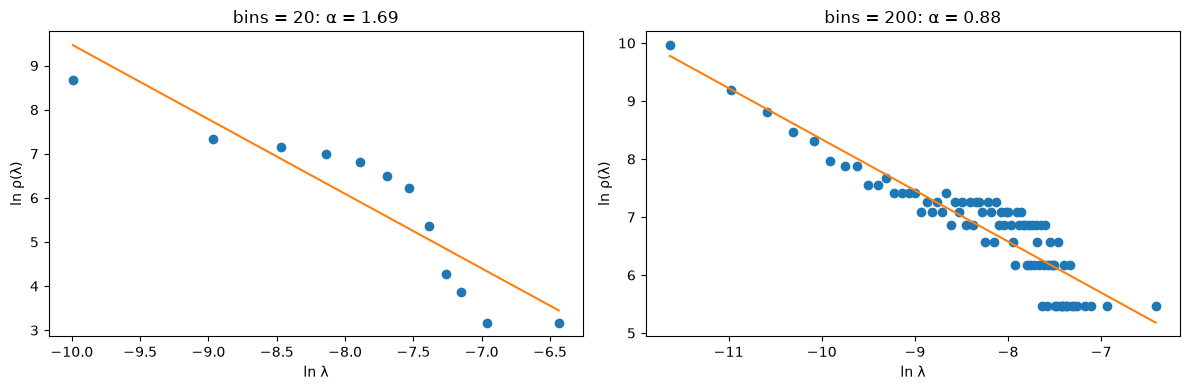

In [9]:
def ols_fit(lam, bins):
    rho, edges = np.histogram(lam, bins=bins, density=True)
    centers = (edges[:-1] + edges[1:]) / 2
    x, y = np.log(centers[rho > 0]), np.log(rho[rho > 0])
    slope, intercept = np.polyfit(x, y, 1)
    return x, y, slope, intercept

for bins in [10, 20, 50, 100, 200]:
    print(f'bins = {bins:3d}: α = {-ols_fit(lam, bins)[2]:.2f}')

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, bins in zip(axes, [20, 200]):
    x, y, slope, intercept = ols_fit(lam, bins)
    ax.plot(x, y, 'o')
    ax.plot(x, slope * x + intercept)
    ax.set_title(f'bins = {bins}: α = {-slope:.2f}')
    ax.set_xlabel('ln λ')
    ax.set_ylabel('ln ρ(λ)')
fig.tight_layout()
plt.show()

**Что делаем.** Оцениваем $\alpha$ методом максимального правдоподобия (оценщик Хилла). Для порога $\lambda_{min}$ берём все $\lambda_i \ge \lambda_{min}$ и считаем
$$\alpha = 1 + N_{tail}\left[\sum_{i=1}^{N_{tail}}\ln\frac{\lambda_i}{\lambda_{min}}\right]^{-1}.$$
Порог перебираем по всем собственным числам (оставляя в хвосте хотя бы 3 точки). Выбираем тот, при котором хвост ближе всего к степенному закону по статистике Колмогорова–Смирнова $D_{KS} = \max|F_{\text{эмп}}(\lambda) - F_{\text{теор}}(\lambda)|$, где $F_{\text{теор}}(\lambda) = 1 - (\lambda/\lambda_{min})^{-(\alpha-1)}$. Это алгоритм Клаузе–Шализи–Ньюмана, по нему же работает библиотека `powerlaw`.

Рисуем эмпирическую CCDF $P(X \ge \lambda)$ в log-log. У степенного хвоста это прямая $P(X \ge \lambda) = \frac{N_{tail}}{N}(\lambda/\lambda_{min})^{-(\alpha-1)}$.

**Зачем.** MLE не нуждается в бинах, использует каждое собственное число и состоятелен: с ростом числа точек сходится к истинному $\alpha$.

**Как рассказать.** «Ниже $\lambda_{min}$ лежит шум, выше — хвост. Для каждого кандидата в $\lambda_{min}$ считаю $\alpha$ по формуле Хилла и KS-расстоянием проверяю, насколько хорошо степенной закон описывает хвост. Беру порог с наименьшим расстоянием. На графике в log-log хвост ложится на прямую.»

α = 6.04, λmin = 4.88e-04, D_KS = 0.041, точек в хвосте: 40 из 512

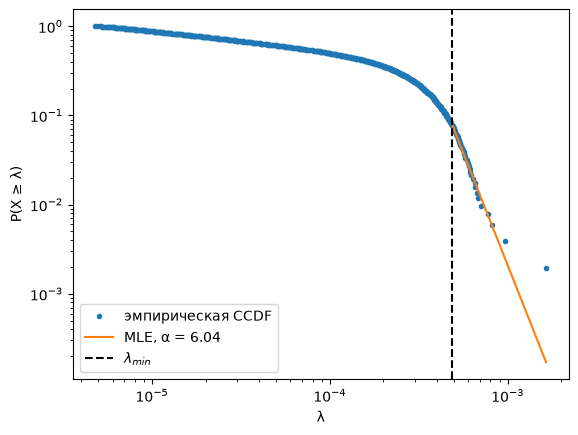

In [10]:
def fit_alpha(lam):
    lam = np.sort(lam)
    best = (np.inf, np.nan, np.nan)
    for lam_min in lam[:-2]:
        tail = lam[lam >= lam_min]
        alpha = 1 + len(tail) / np.sum(np.log(tail / lam_min))
        cdf = 1 - (tail / lam_min)**(1 - alpha)
        D = np.max(np.abs(np.arange(len(tail)) / len(tail) - cdf))
        best = min(best, (D, alpha, lam_min))
    return best

D, alpha, lam_min = fit_alpha(lam)
print(f'α = {alpha:.2f}, λmin = {lam_min:.2e}, D_KS = {D:.3f}, точек в хвосте: {(lam >= lam_min).sum()} из {len(lam)}')

lam_sorted = np.sort(lam)
tail = lam_sorted[lam_sorted >= lam_min]
fig, ax = plt.subplots()
ax.loglog(lam_sorted, 1 - np.arange(len(lam)) / len(lam), '.', label='эмпирическая CCDF')
ax.loglog(tail, len(tail) / len(lam) * (tail / lam_min)**(1 - alpha), label=f'MLE, α = {alpha:.2f}')
ax.axvline(lam_min, ls='--', c='k', label=r'$\lambda_{min}$')
ax.set_xlabel('λ')
ax.set_ylabel('P(X ≥ λ)')
ax.legend()
plt.show()

**Что делаем.** Проводим слепой тест на четырёх слоях:
1. `layer1.0.conv1` — веса заменяем шумом $\mathcal{N}(0, \sigma^2)$ с тем же $\sigma$, что у исходных весов (так выглядит необученный слой);
2. `layer2.0.conv1` — оставляем как есть;
3. `layer3.0.conv1` — делаем SVD, оставляем два старших сингулярных числа, остальные зануляем и собираем матрицу обратно (ранг 2);
4. `fc` — выходной слой как есть.

Для каждого слоя строим гистограмму спектра (ось Y логарифмическая, чтобы были видны одиночные числа) и считаем stable rank $\mathrm{srank} = \sum\lambda_i/\lambda_{max}$, показатель $\alpha$ и границу шума $\lambda_+ = \sigma^2(1+\sqrt{\gamma})^2$, где $\gamma = \min(M, K)/\max(M, K)$, а $\sigma^2$ — дисперсия весов слоя.

**Зачем stable rank.** $\sum\lambda_i = \|W\|_F^2/N$ — вся энергия слоя, а $\lambda_{max} = \|W\|_2^2/N$ — энергия самого сильного направления. Их отношение показывает, на сколько направлений энергия реально размазана.

**Зачем $\lambda_+$.** Это строгий тест на шум (колонки `λ > λ+` и `λmax / λ+` в таблице). У случайной матрицы все собственные числа лежат в $[\lambda_-, \lambda_+]$ с точностью до флуктуаций порядка $n^{-2/3}$, а степенной хвост — это собственные числа далеко за $\lambda_+$. Если за $\lambda_+$ ничего нет, то и хвоста нет, какое бы $\alpha$ ни вернула подгонка. Для нулей коллапсированного слоя используем `drop_zeros` из задания 1.

**Как рассказать.** «Беру четыре слоя с заранее известным состоянием и проверяю, различает ли их диагностика без данных. Главные признаки: сколько собственных чисел вышло за границу шума, stable rank и $\alpha$.»

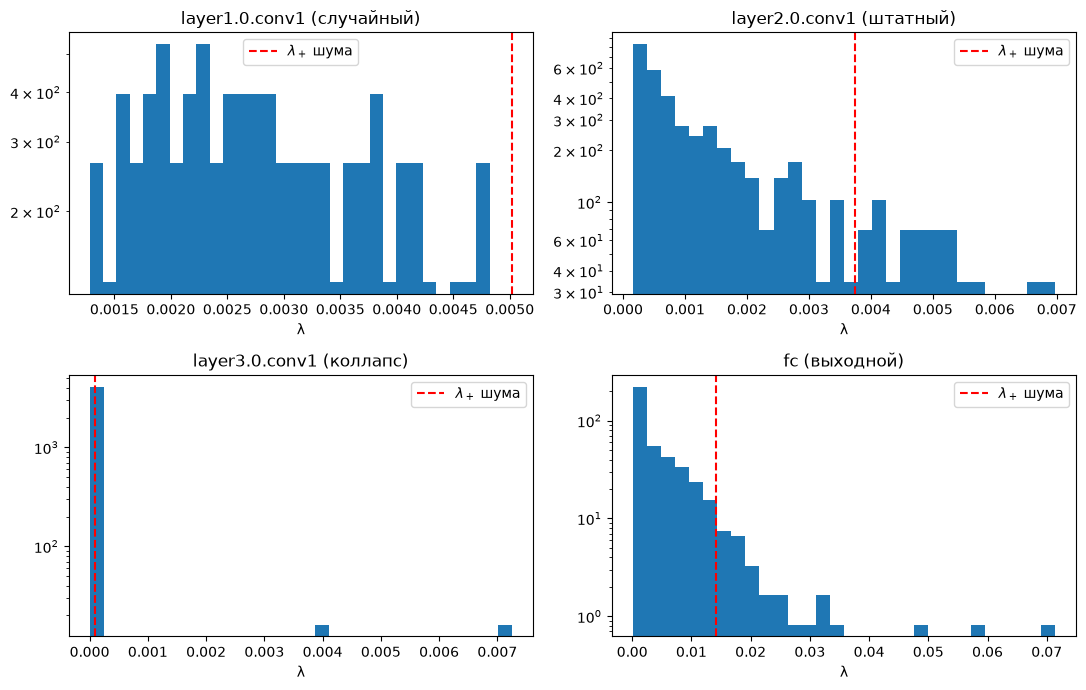

,srank,α,точек в хвосте,λ > λ+,λmax / λ+
слой,,,,,
layer1.0.conv1 (случайный),37.47,10.02,14,0 из 64,0.96
layer2.0.conv1 (штатный),31.78,9.38,10,18 из 128,1.86
layer3.0.conv1 (коллапс),1.55,NaN,0,2 из 256,79.67
fc (выходной),34.60,3.38,59,35 из 512,5.03


In [11]:
W1 = get_weight('layer1.0.conv1')
W3 = get_weight('layer3.0.conv1')
U, S, Vt = np.linalg.svd(W3.reshape(len(W3), -1), full_matrices=False)
S[2:] = 0

layers = {
    'layer1.0.conv1 (случайный)': rng.normal(0, W1.std(), W1.shape),
    'layer2.0.conv1 (штатный)': get_weight('layer2.0.conv1'),
    'layer3.0.conv1 (коллапс)': U @ np.diag(S) @ Vt,
    'fc (выходной)': get_weight('fc'),
}

rows = []
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for ax, (name, W) in zip(axes.flat, layers.items()):
    lam = esd(W)
    shape = W.reshape(len(W), -1).shape
    noise_edge = mp_bounds(min(shape) / max(shape), W.var())[1]
    D, alpha, lam_min = fit_alpha(drop_zeros(lam))

    ax.hist(lam, bins=30, density=True, log=True)
    ax.axvline(noise_edge, ls='--', c='r', label=r'$\lambda_+$ шума')
    ax.set_title(name)
    ax.set_xlabel('λ')
    ax.legend()

    rows.append({
        'слой': name,
        'srank': lam.sum() / lam.max(),
        'α': alpha,
        'точек в хвосте': (lam >= lam_min).sum(),
        'λ > λ+': f'{(lam > noise_edge).sum()} из {len(lam)}',
        'λmax / λ+': lam.max() / noise_edge,
    })

fig.tight_layout()
plt.show()
pd.DataFrame(rows).set_index('слой').round(2)

**Итоговый вывод.** Сопоставляем слои с пятью фазами Мартина–Махони из конспекта.

| слой | что видно | фаза |
|---|---|---|
| `layer1.0.conv1` (случайный) | 0 из 64 собственных чисел за $\lambda_+$, $\lambda_{max}/\lambda_+ \approx 0.96 < 1$: весь спектр внутри балка МП. Подгонка вернула $\alpha \approx 10$, но это артефакт: она нашла «хвост» у правого края балка, где плотность просто падает до нуля. Настоящий хвост лежал бы далеко за $\lambda_+$ | 1. Random-like: чистый белый шум |
| `layer2.0.conv1` (штатный) | 18 из 128 чисел за $\lambda_+$, максимум в 1.9 раза больше $\lambda_+$, srank ≈ 32: структура выучена. Но хвост короткий (10 точек) и крутой, $\alpha \approx 9.4 > 4$ | 2–3. Bleeding out / Bulk + Decay: слой обучен, но тяжёлого хвоста не сформировал |
| `layer3.0.conv1` (коллапс) | ненулевых собственных чисел всего 2 из 256, srank ≈ 1.55: почти вся энергия в одном направлении. Непрерывного спектра нет, и $\alpha$ подгонять не к чему | 5. Collapsed: коллапс ранга |
| `fc` (выходной) | длинный хвост до $5\lambda_+$, 35 чисел за $\lambda_+$, $\alpha \approx 3.4 \in (2, 4]$ | 4. Heavy-Tailed: «зона Златовласки» |

Оптимальный режим у `fc`, выродился `layer3.0.conv1`, чистым шумом остался `layer1.0.conv1`.